# Extension — Sélection de variables avant clustering

**Projet final « Apprentissage non supervisé » — Segmentation de clientèle bancaire**

Extension optionnelle n° 2 du sujet : *comparer plusieurs méthodes de sélection de caractéristiques (variance, wrapper) avant clustering.*

En apprentissage non supervisé, il n'y a pas de cible pour dire quelles variables sont « utiles ». On compare donc des critères **internes** :

| Méthode | Famille | Principe |
|---|---|---|
| Filtre **variance** | filtre | on retire les colonnes qui varient presque pas (après mise à l'échelle [0, 1]) |
| Filtre **score laplacien** | filtre | une bonne variable prend des valeurs proches pour des clients voisins (graphe des 10 plus proches voisins) |
| **Wrapper naïf** | wrapper | sélection avant ; critère = silhouette de K-means **dans le sous-espace** des variables retenues |
| **Wrapper corrigé** | wrapper | élimination arrière ; critère = silhouette de Ward **dans l'espace complet** des 15 variables |

Chaque sous-ensemble est ensuite segmenté par la **même méthode** que la solution retenue (CAH de Ward, k = 4) et comparé à la référence (15 variables). `y` ne sert, comme au Jour 4, qu'au contrôle a posteriori.

In [1]:
# Mise en forme : toutes les bordures sur tous les tableaux du notebook
from IPython.display import HTML, display
display(HTML("<style>table, th, td {border: 1px solid #333 !important; border-collapse: collapse !important;} th, td {padding: 4px 8px !important;}</style>"))

In [2]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, pairwise_distances
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import MinMaxScaler

from src.config import SEED, FIG, TAB, LAB, GOWER_CACHE
from src import preprocessing as pp
from src.clustering_utils import gower_matrix

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

d = pp.prepare_all()
X_a, X_mixed = d["X_a"], d["X_mixed"]
y_bin = (d["y"] == "yes").astype(int).values
D_full = pairwise_distances(X_a.values)                 # espace complet (représentation (a))
D_gow = gower_matrix(X_mixed, cache=GOWER_CACHE)
ref = pd.read_csv(LAB / "segments_final_echantillon.csv", index_col=0)["segment"].values   # Ward k = 4, 15 variables

VARS = pp.ACTIVE_NUM + pp.ACTIVE_CAT
COLS = {v: [c for c in X_a.columns if c == v or c.startswith(v + "_")] for v in VARS}   # colonnes encodées par variable
cols_of = lambda sub: sum([COLS[v] for v in sub], [])
print(f"{len(VARS)} variables actives, {X_a.shape[1]} colonnes encodées, {len(X_a)} clients")

15 variables actives, 37 colonnes encodées, 4000 clients


## 1. Filtre par variance
Les colonnes sont ramenées sur [0, 1] (sinon les variables standardisées auraient toutes une variance de 1). On retire celles dont la variance est inférieure à **0,01**.

Colonnes retirées : ['default_yes', 'education_illiterate', 'previous']


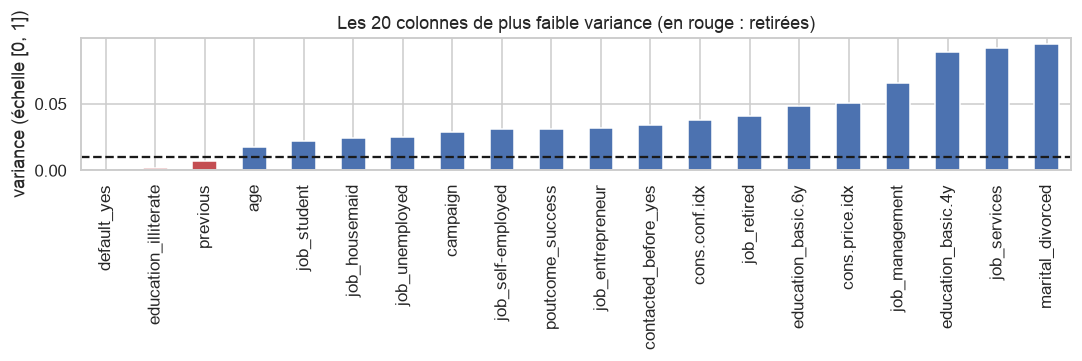

In [3]:
mm = pd.DataFrame(MinMaxScaler().fit_transform(X_a), columns=X_a.columns)
variances = mm.var().sort_values()
SEUIL = 0.01
drop_var = variances[variances < SEUIL].index.tolist()
keep_var_cols = [c for c in X_a.columns if c not in drop_var]
print("Colonnes retirées :", drop_var)

fig, ax = plt.subplots(figsize=(10, 3.4))
variances.head(20).plot.bar(ax=ax, color=["#C44E52" if v < SEUIL else "#4C72B0" for v in variances.head(20)])
ax.axhline(SEUIL, ls="--", color="k"); ax.set_ylabel("variance (échelle [0, 1])")
ax.set_title("Les 20 colonnes de plus faible variance (en rouge : retirées)")
plt.tight_layout(); plt.savefig(FIG / "07_variance.png", bbox_inches="tight"); plt.show()

**Lecture.** Le filtre retire deux modalités presque vides (`default_yes`, `education_illiterate`), ce qui est raisonnable, mais aussi **`previous`**. Cette variable a une faible variance parce que 86 % des clients ne sont jamais démarchés ; or c'est elle qui définit le segment S3. Une faible variance ne veut pas dire une faible information : c'est la limite connue de ce filtre.

## 2. Filtre par score laplacien
On construit le graphe des 10 plus proches voisins des clients (noyau gaussien sur les distances). Le **score laplacien** d'une colonne est faible quand elle prend des valeurs proches sur des clients voisins, c'est-à-dire quand elle respecte la structure locale des données (He, Cai et Niyogi, 2005). Le score d'une variable catégorielle est la moyenne de ses indicatrices. On garde les **8 meilleures variables** sur 15.

Variables retenues : ['euribor3m', 'previous', 'cons.conf.idx', 'cons.price.idx', 'poutcome', 'contact', 'age', 'default']


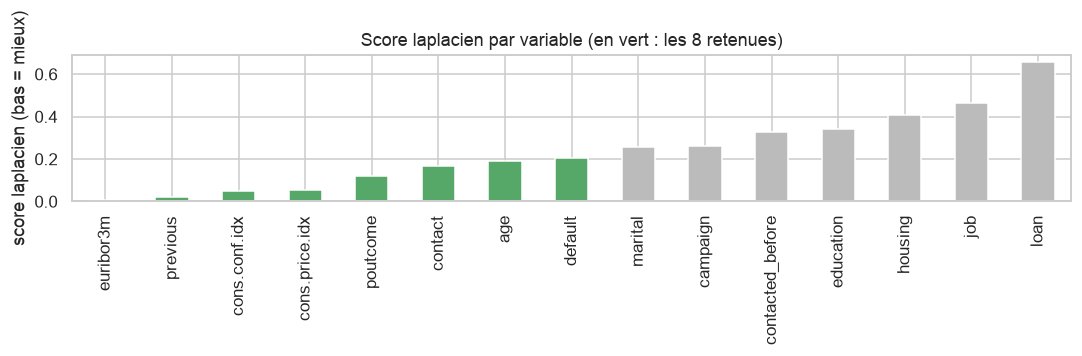

In [4]:
W = kneighbors_graph(X_a.values, 10, mode="distance", include_self=False)
W = 0.5 * (W + W.T)
t = np.median(W.data)
W.data = np.exp(-(W.data ** 2) / t ** 2)
deg = np.asarray(W.sum(axis=1)).ravel()
L = np.diag(deg) - W.toarray()

def laplacian_score(f):
    f = f - (f @ deg) / deg.sum()
    den = f @ (deg * f)
    return (f @ L @ f) / den if den > 0 else np.nan

col_score = {c: laplacian_score(X_a[c].values.astype(float)) for c in X_a.columns}
lap = pd.Series({v: np.nanmean([col_score[c] for c in COLS[v]]) for v in VARS}).sort_values()
sel_lap = lap.index[:8].tolist()
print("Variables retenues :", sel_lap)

fig, ax = plt.subplots(figsize=(10, 3.2))
lap.plot.bar(ax=ax, color=["#55A868" if v in sel_lap else "#BBBBBB" for v in lap.index])
ax.set_ylabel("score laplacien (bas = mieux)"); ax.set_title("Score laplacien par variable (en vert : les 8 retenues)")
plt.tight_layout(); plt.savefig(FIG / "07_laplacien.png", bbox_inches="tight"); plt.show()

## 3. Wrappers
Un wrapper choisit les variables **en lançant le clustering** et en jugeant le résultat.

- **Wrapper naïf** — sélection avant : à chaque étape, on ajoute la variable qui donne la meilleure silhouette de K-means (k = 4) **calculée dans le sous-espace retenu**, avec au moins 5 % des clients par cluster.
- **Wrapper corrigé** — élimination arrière : on part des 15 variables et on retire à chaque étape celle dont l'absence dégrade le moins la silhouette de Ward (k = 4), **toujours calculée dans l'espace complet**. Toutes les partitions sont ainsi jugées sur la même base.

Wrapper naïf : 1re variable choisie = euribor3m (silhouette 0.89)
Wrapper corrigé : variables retenues = ['previous', 'cons.conf.idx', 'euribor3m']


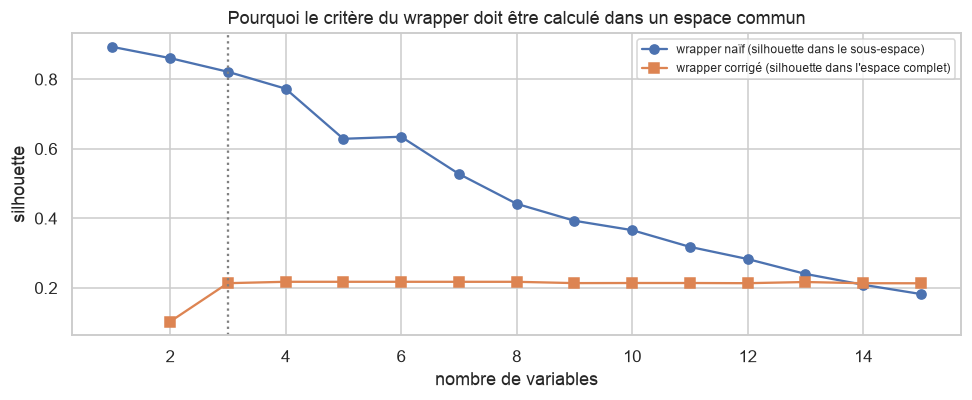

,nb variables,variable retirée,silhouette (espace complet)
0,15,—,0.213
1,14,job,0.213
2,13,marital,0.217
3,12,contacted_before,0.213
4,11,housing,0.214
5,10,default,0.214
6,9,poutcome,0.214
7,8,age,0.217
8,7,campaign,0.217
9,6,loan,0.217


In [5]:
# Wrapper naïf (sélection avant, silhouette dans le sous-espace)
sel, rest, naive = [], VARS.copy(), []
while rest:
    best = None
    for v in rest:
        X = X_a[cols_of(sel + [v])].values
        lab = KMeans(n_clusters=4, n_init=3, random_state=SEED).fit_predict(X)
        if np.bincount(lab, minlength=4).min() / len(lab) < 0.05:
            continue
        s = silhouette_score(X, lab)
        if best is None or s > best[1]:
            best = (v, s)
    if best is None:
        break
    sel.append(best[0]); rest.remove(best[0])
    naive.append({"nb variables": len(sel), "variable ajoutée": best[0], "silhouette (sous-espace)": best[1]})
naive = pd.DataFrame(naive)

# Wrapper corrigé (élimination arrière, silhouette dans l'espace complet)
def full_space_silhouette(sub):
    lab = AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(X_a[cols_of(sub)].values)
    if np.bincount(lab).min() / len(lab) < 0.05:
        return -1.0
    return silhouette_score(D_full, lab, metric="precomputed")

cur = VARS.copy()
backward = [{"nb variables": len(cur), "variable retirée": "—", "silhouette (espace complet)": full_space_silhouette(cur)}]
while len(cur) > 2:
    s, v = max((full_space_silhouette([u for u in cur if u != w]), w) for w in cur)
    cur.remove(v)
    backward.append({"nb variables": len(cur), "variable retirée": v, "silhouette (espace complet)": s})
backward = pd.DataFrame(backward)

# Sous-ensemble retenu : le plus petit dont la silhouette reste à moins de 0,005 du maximum
smax = backward["silhouette (espace complet)"].max()
k_min = backward.loc[backward["silhouette (espace complet)"] >= smax - 0.005, "nb variables"].min()
removed = backward.loc[backward["nb variables"] >= k_min, "variable retirée"].iloc[1:].tolist()
sel_wrap = [v for v in VARS if v not in removed]
print("Wrapper naïf : 1re variable choisie =", naive.iloc[0, 1], f"(silhouette {naive.iloc[0, 2]:.2f})")
print("Wrapper corrigé : variables retenues =", sel_wrap)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(naive["nb variables"], naive["silhouette (sous-espace)"], "o-", label="wrapper naïf (silhouette dans le sous-espace)")
ax.plot(backward["nb variables"], backward["silhouette (espace complet)"], "s-", label="wrapper corrigé (silhouette dans l'espace complet)")
ax.axvline(k_min, ls=":", color="grey"); ax.set_xlabel("nombre de variables"); ax.set_ylabel("silhouette")
ax.set_title("Pourquoi le critère du wrapper doit être calculé dans un espace commun"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "07_wrappers.png", bbox_inches="tight"); plt.show()
backward.round(3)

## 4. Comparaison des sous-ensembles
Chaque sous-ensemble est segmenté par la CAH de Ward (k = 4). On mesure :
- la **qualité interne**, toujours dans l'espace complet (silhouette euclidienne et de Gower, Davies-Bouldin) pour que les sous-ensembles soient comparables ;
- la **stabilité** (ARI bootstrap, 20 rééchantillons, comme au Jour 4) ;
- l'**accord avec la solution retenue** (ARI) ;
- à titre de contrôle seulement, l'écart de taux de souscription entre segments.

In [6]:
subsets = {
    "Toutes (référence)": X_a.columns.tolist(),
    "Filtre variance": keep_var_cols,
    "Filtre laplacien (8)": cols_of(sel_lap),
    f"Wrapper naïf (1 : {naive.iloc[0, 1]})": cols_of([naive.iloc[0, 1]]),
    f"Wrapper corrigé ({len(sel_wrap)})": cols_of(sel_wrap),
}
rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(X_a), len(X_a)) for _ in range(20)]
rows, labels = [], {}
for name, cs in subsets.items():
    X = X_a[cs].values
    lab = AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(X)
    labels[name] = lab
    stab = np.mean([adjusted_rand_score(lab[ib], AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(X[ib]))
                    for ib in boot_idx])
    rates = 100 * pd.Series(y_bin).groupby(lab).mean()
    rows.append({"sous-ensemble": name, "nb colonnes": len(cs),
                 "plus petit cluster (%)": 100 * np.bincount(lab).min() / len(lab),
                 "silhouette (espace complet)": silhouette_score(D_full, lab, metric="precomputed"),
                 "silhouette Gower": silhouette_score(D_gow, lab, metric="precomputed"),
                 "Davies-Bouldin (espace complet)": davies_bouldin_score(X_a.values, lab),
                 "stabilité (ARI bootstrap)": stab,
                 "ARI avec la solution retenue": adjusted_rand_score(ref, lab),
                 "taux souscr. min (%)": rates.min(), "taux souscr. max (%)": rates.max()})
comp = pd.DataFrame(rows)
comp.to_csv(TAB / "07_selection_variables.csv", index=False)
comp.style.format(precision=3).format({"plus petit cluster (%)": "{:.1f}", "taux souscr. min (%)": "{:.1f}",
                                       "taux souscr. max (%)": "{:.1f}"}).hide(axis="index")

sous-ensemble,nb colonnes,plus petit cluster (%),silhouette (espace complet),silhouette Gower,Davies-Bouldin (espace complet),stabilité (ARI bootstrap),ARI avec la solution retenue,taux souscr. min (%),taux souscr. max (%)
Toutes (référence),37,5.8,0.213139,0.173281,1.731009,0.931698,1.000000,5.1,39.7
Filtre variance,34,6.3,0.181752,0.087475,1.853884,0.896914,0.669801,2.8,41.7
Filtre laplacien (8),12,5.7,0.213666,0.174098,1.718182,0.967762,0.993777,5.1,39.5
Wrapper naïf (1 : euribor3m),1,9.8,0.076973,0.110376,2.433344,0.999930,0.735638,4.9,46.1
Wrapper corrigé (3),3,6.8,0.213404,0.177972,1.679258,0.991030,0.973258,5.1,44.5


**Lecture.**

| Sous-ensemble | Verdict |
|---|---|
| **Filtre variance** | Le plus mauvais des filtres : en retirant `previous`, il fait disparaître le segment des clients déjà démarchés (accord de 0,67 seulement avec la solution retenue, silhouette en baisse). |
| **Filtre laplacien** (8 variables) | Retrouve la solution retenue presque à l'identique (ARI 0,99), avec la même qualité et une stabilité un peu meilleure (0,97). Les 7 variables écartées (profession, statut marital, études, prêts, nombre d'appels, `contacted_before`) n'apportaient pas de structure. |
| **Wrapper naïf** | Piégé par son critère : une silhouette calculée sur une seule variable est mécaniquement élevée (0,89), mais la partition obtenue est médiocre dès qu'on la juge sur l'ensemble des données (silhouette de 0,08 dans l'espace complet). |
| **Wrapper corrigé** (3 variables) | Avec seulement `euribor3m`, `cons.conf.idx` et `previous`, il retrouve la solution retenue (ARI 0,97), avec une qualité égale ou meilleure (Davies-Bouldin 1,68 au lieu de 1,73) et la stabilité la plus forte (0,99). |

**Conséquences.**
1. **Le critère d'un wrapper non supervisé doit être calculé dans un espace commun** à tous les sous-ensembles. Sinon il favorise mécaniquement les sous-espaces de petite dimension.
2. La segmentation retenue est **portée par trois variables** : le contexte économique (Euribor, confiance des ménages) et l'historique de contact. C'est la même conclusion que l'analyse de sensibilité du notebook 06, obtenue ici par une autre voie.
3. On garde les 15 variables pour la solution finale : elles ne dégradent pas la partition et elles enrichissent la **description** des segments (profession, âge, études). Mais un modèle à 3 variables suffirait pour **affecter** un nouveau client.

## Bilan
- Quatre méthodes de sélection comparées : deux filtres (variance, score laplacien) et deux wrappers (naïf et corrigé).
- Le filtre par variance est trompeur sur des variables asymétriques ; le score laplacien et le wrapper corrigé convergent vers les mêmes variables clés.
- Trois variables suffisent à reproduire la segmentation (ARI 0,97) : elle repose sur le **contexte économique** et l'**historique de contact**.